In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the raw weather dataset
df = pd.read_parquet("weather_data.parquet")

# Display the first five rows
display(df.head())

# Check the dataset dimensions
print("Dataset shape:", df.shape)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,snow_depth,location
0,2024-10-01T00:00,16.1,82,0.0,5.4,0.0,Grenoble
1,2024-10-01T01:00,15.8,85,0.0,4.9,0.0,Grenoble
2,2024-10-01T02:00,15.8,84,0.0,4.7,0.0,Grenoble
3,2024-10-01T03:00,15.7,86,0.0,5.0,0.0,Grenoble
4,2024-10-01T04:00,15.7,86,0.0,4.9,0.0,Grenoble


Dataset shape: (52560, 7)


In [2]:
# Check missing values
print("Missing values:")
print(df.isna().sum())

# Check duplicate observations
print("Duplicate observations:", df.duplicated(subset=["location", "time"]).sum())

Missing values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
snow_depth              0
location                0
dtype: int64
Duplicate observations: 0


In [3]:
# Check physically invalid values
print("Invalid humidity:", ((df["relative_humidity_2m"] < 0) | (df["relative_humidity_2m"] > 100)).sum())

print("Negative precipitation:", (df["precipitation"] < 0).sum())

print("Negative wind speed:", (df["wind_speed_10m"] < 0).sum())

print("Negative snow depth:", (df["snow_depth"] < 0).sum())

Invalid humidity: 0
Negative precipitation: 0
Negative wind speed: 0
Negative snow depth: 0


In [4]:
# Create a copy of the dataset
df_clean = df.copy()

# Convert time to datetime
df_clean["time"] = pd.to_datetime(df_clean["time"])

# Sort observations by location and time
df_clean = df_clean.sort_values(["location", "time"]).reset_index(drop=True)

# Save the cleaned dataset
df_clean.to_parquet("weather_data_clean.parquet", index=False)

print("Cleaned dataset shape:", df_clean.shape)

Cleaned dataset shape: (52560, 7)


In [5]:
# Extract the date from each timestamp
df_clean["date"] = df_clean["time"].dt.date

# Display the first five rows
display(df_clean.head())

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,snow_depth,location,date
0,2024-10-01 00:00:00,8.6,69,0.0,0.4,0.0,Chamrousse,2024-10-01
1,2024-10-01 01:00:00,7.5,82,0.0,3.6,0.0,Chamrousse,2024-10-01
2,2024-10-01 02:00:00,7.8,79,0.0,3.5,0.0,Chamrousse,2024-10-01
3,2024-10-01 03:00:00,8.0,76,0.0,3.3,0.0,Chamrousse,2024-10-01
4,2024-10-01 04:00:00,7.3,80,0.0,4.1,0.0,Chamrousse,2024-10-01


In [6]:
# Aggregate hourly weather data into daily weather profiles
df_daily = df_clean.groupby(["location", "date"]).agg({
    "temperature_2m": "mean",
    "relative_humidity_2m": "mean",
    "precipitation": "sum",
    "wind_speed_10m": "mean",
    "snow_depth": "mean"
}).reset_index()

display(df_daily.head())

print("Daily dataset shape:", df_daily.shape)

,location,date,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,snow_depth
0,Chamrousse,2024-10-01,9.329167,82.625000,6.8,5.154167,0.0
1,Chamrousse,2024-10-02,6.004167,95.500000,14.9,4.908333,0.0
2,Chamrousse,2024-10-03,3.333333,94.875000,1.7,5.575000,0.0
3,Chamrousse,2024-10-04,1.775000,93.375000,0.7,5.666667,0.0
4,Chamrousse,2024-10-05,1.995833,83.458333,0.0,3.512500,0.0


Daily dataset shape: (2190, 7)


### Exploratory Data Analysis (EDA)

Before clustering, we examined the weather data to assess its quality.

- No missing values or duplicate observations were found.
- No irregular hourly intervals were detected.
- No invalid weather values were identified.
- We explored the distributions and differences between the three locations.

The dataset was suitable for daily aggregation and clustering.

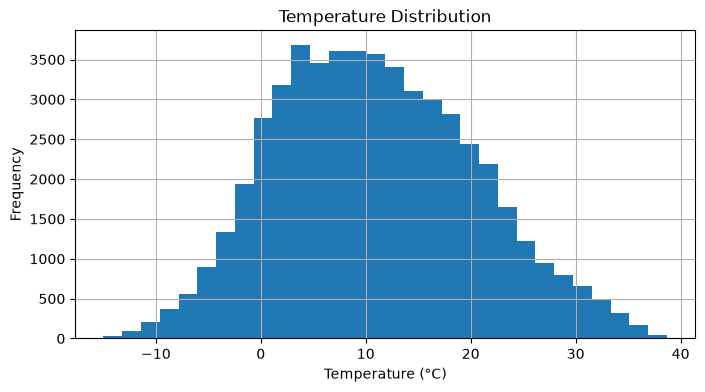

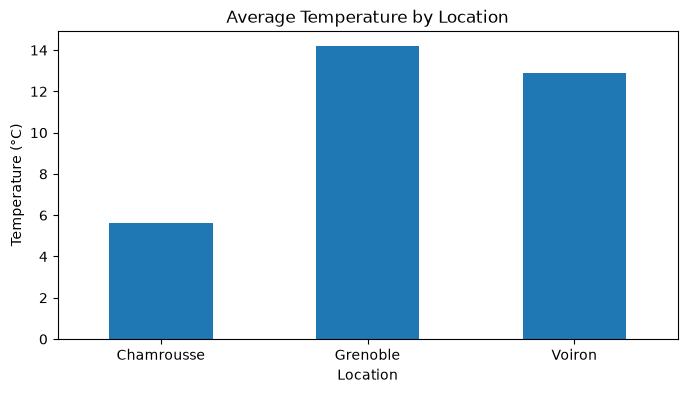

In [7]:
# Plot the distribution of temperature
df_clean["temperature_2m"].hist(bins=30, figsize=(8, 4))

plt.title("Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.show()

# Compare average temperature by location
df_clean.groupby("location")["temperature_2m"].mean().plot(
    kind="bar", figsize=(8, 4)
)

plt.title("Average Temperature by Location")
plt.xlabel("Location")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=0)
plt.show()

In [9]:
from sklearn.preprocessing import StandardScaler

# Select the weather features for clustering
features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "snow_depth"
]

X = df_daily[features]

# Standardize the weather features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original data:")
display(X.head())

print("Standardized data:")
print(X_scaled[:5])

Original data:


,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,snow_depth
0,9.329167,82.625000,6.8,5.154167,0.0
1,6.004167,95.500000,14.9,4.908333,0.0
2,3.333333,94.875000,1.7,5.575000,0.0
3,1.775000,93.375000,0.7,5.666667,0.0
4,1.995833,83.458333,0.0,3.512500,0.0


Standardized data:
[[-0.17965338  0.67715378  0.4028185   0.22470264 -0.39197253]
 [-0.55885841  1.58647814  1.45266897  0.11913698 -0.39197253]
 [-0.86345794  1.54233618 -0.25819847  0.40541673 -0.39197253]
 [-1.04118059  1.43639547 -0.38780964  0.44478019 -0.39197253]
 [-1.0159953   0.73600972 -0.47853746 -0.48026124 -0.39197253]]


In [10]:
from sklearn.cluster import KMeans

# Create a K-means model with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model and assign each day to a cluster
df_daily["cluster"] = kmeans.fit_predict(X_scaled)

# Count the days in each cluster
print(df_daily["cluster"].value_counts().sort_index())

cluster
0     225
1    1199
2     766
Name: count, dtype: int64


In [11]:
# Calculate the average weather conditions for each cluster
cluster_summary = df_daily.groupby("cluster")[features].mean()

display(cluster_summary.round(2))

,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,snow_depth
cluster,,,,,
0,-1.12,69.60,4.81,3.26,0.93
1,7.82,81.92,5.38,4.73,0.03
2,19.26,60.14,0.73,4.87,0.01


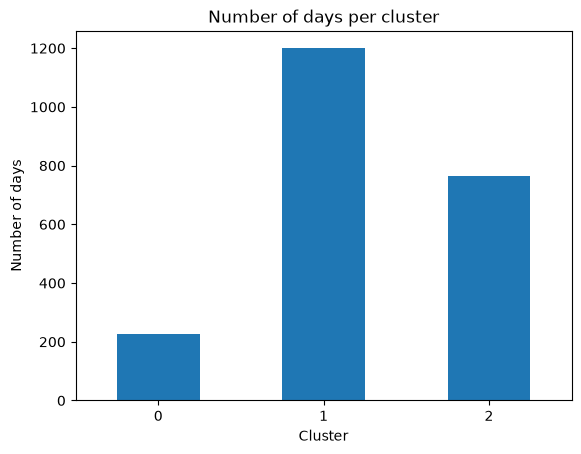

In [12]:
# Count the number of days in each cluster
cluster_counts = df_daily["cluster"].value_counts().sort_index()

# Plot the cluster sizes
cluster_counts.plot(kind="bar")

plt.title("Number of days per cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of days")
plt.xticks(rotation=0)
plt.show()

In [13]:
# Count the days in each cluster for each location
location_clusters = pd.crosstab(
    df_daily["location"],
    df_daily["cluster"]
)

display(location_clusters)

cluster,0,1,2
location,,,
Chamrousse,218,315,197
Grenoble,7,411,312
Voiron,0,473,257


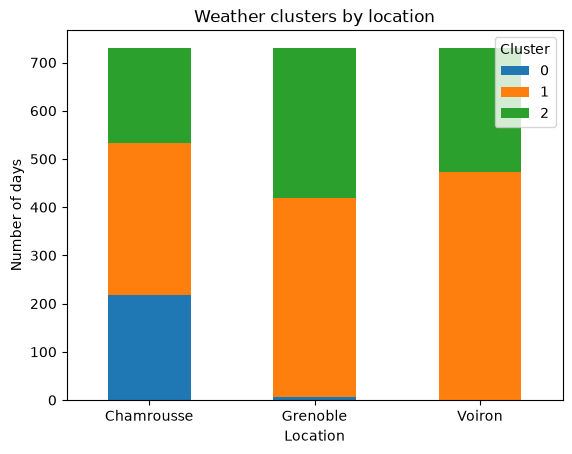

In [14]:
# Plot the distribution of clusters by location
location_clusters.plot(kind="bar", stacked=True)

plt.title("Weather clusters by location")
plt.xlabel("Location")
plt.ylabel("Number of days")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.show()

In [15]:
from sklearn.metrics import silhouette_score

# Evaluate the quality of the clustering
score = silhouette_score(X_scaled, df_daily["cluster"])

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.283


In [16]:
# Compare different numbers of clusters
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f"k={k}: Silhouette Score = {score:.3f}")

k=2: Silhouette Score = 0.421
k=3: Silhouette Score = 0.283
k=4: Silhouette Score = 0.317
k=5: Silhouette Score = 0.335
k=6: Silhouette Score = 0.309


In [17]:
# Train the final K-means model with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

# Assign each day to a cluster
df_daily["cluster"] = kmeans.fit_predict(X_scaled)

# Display the number of days in each cluster
print(df_daily["cluster"].value_counts().sort_index())

cluster
0     235
1    1955
Name: count, dtype: int64


In [18]:
# Calculate the average weather conditions for each cluster
cluster_summary = df_daily.groupby("cluster")[features].mean()

display(cluster_summary.round(2))

,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,snow_depth
cluster,,,,,
0,-1.23,70.29,5.03,3.31,0.91
1,12.36,73.37,3.53,4.79,0.02


cluster,0,1
location,,
Chamrousse,227,503
Grenoble,8,722
Voiron,0,730


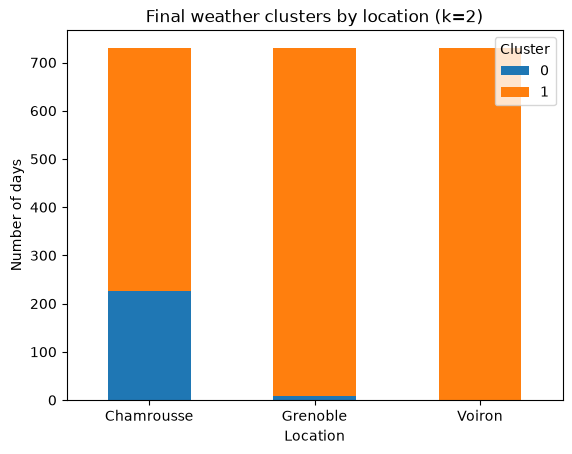

In [19]:
# Count the days in each cluster for each location
location_clusters = pd.crosstab(
    df_daily["location"],
    df_daily["cluster"]
)

# Display the results
display(location_clusters)

# Plot the cluster distribution by location
location_clusters.plot(kind="bar", stacked=True)

plt.title("Final weather clusters by location (k=2)")
plt.xlabel("Location")
plt.ylabel("Number of days")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.show()

In [20]:
# Save the final daily weather dataset with cluster labels
df_daily.to_parquet("weather_clusters.parquet", index=False)

# Check the final dataset
print("Final dataset shape:", df_daily.shape)
print("Clusters:", df_daily["cluster"].unique())

Final dataset shape: (2190, 8)
Clusters: [1 0]


### Clustering Results

We used K-Means to group daily weather observations based on five weather features.

We selected k=2 because it achieved the highest silhouette score (0.421).

- Cluster 0: colder and snowier days.
- Cluster 1: other weather conditions.

The results reveal two main weather profiles across Grenoble, Chamrousse, and Voiron.

### Interpretation of the smaller cluster

Cluster 0 contains 235 days, including 227 days from Chamrousse and 8 days from Grenoble.

This cluster is characterized by low temperatures and significant snow depth. Since Chamrousse is located in the mountains, these results are coherent with its geographical characteristics.

The smaller size of this cluster does not necessarily indicate a data-quality problem. It mainly represents less frequent cold and snowy weather conditions.

However, additional checks would be needed to completely rule out data-quality issues.